# H6 · Stagnation: progress in bits, not atoms (*Zero to One*, ch. 1 and conclusion)

Thiel argues that, outside computers and communications, technological progress has slowed sharply since the early 1970s. "Technology" has come to mean information technology, while energy, transport, medicine and construction have stalled. The book ends by asking whether we face stagnation or takeoff, and lists four scenarios: recurrent collapse, plateau, extinction, takeoff.

| Claim | Test | Data (FRED) |
|---|---|---|
| **H6a.** Productivity growth slowed after the early 1970s, except for the IT boom. Has it revived since the book? | Annual growth of labour productivity (nonfarm business output per hour) and total factor productivity by period: 1948–73, 1973–95, 1995–2004, 2004–14, 2014–latest. | `OPHNFB`; `RTFPNAUSA632NRUG` (Penn World Table TFP) |
| **H6b.** Progress shows up in bits, not atoms. | Prices relative to the overall CPI for "bits" goods (computers, software, TVs, phone service) against "atoms" goods and services (tuition, medical care, rent, airfares, electricity, new cars, food), 2000–2014 against 2014–latest. A good whose quality-adjusted price falls relative to the CPI is getting cheaper to produce, which is one footprint of progress. | BLS CPI components |
| **H6c.** Investment has moved from physical to intangible capital. | Shares of business investment going to structures, equipment and intellectual property (software, R&D, entertainment originals), 1947–latest. | BEA via FRED |
| **H6d.** Medicine, an "atoms" field Thiel names, has stalled. | Gains in US life expectancy at birth by decade. | World Bank via FRED |

**Caveats**
* Relative prices measure the cost of a good, not its value; BLS quality adjustment for computers and TVs is large and debated.
* Services such as tuition and medical care rise in relative price partly because of Baumol's cost disease (wages rise everywhere, productivity in labour-intensive services does not), not only because innovation stalled.
* The 2020–21 pandemic years distort both productivity and life expectancy; results are shown with and without them where it matters.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
import sys; from pathlib import Path  # thiel_common.py lives in the repo root
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "thiel_common.py").exists())))
import thiel_common as tc
tc.style()
print("synthetic mode" if tc.SYNTHETIC else "live data")

def annual(s):
    a = s.groupby(s.index.year).mean()
    n = s.groupby(s.index.year).size()
    full = n >= n.max() if len(n) else n
    return a[full | (n.index < n.index.max())]           # drop a partial final year

PERIODS = [(1948, 1973), (1973, 1995), (1995, 2004), (2004, 2014), (2014, None)]
def growth_table(a, periods=PERIODS):
    rows = []
    last, first = int(a.index.max()), int(a.index.min())
    for a0, a1 in periods:
        a1 = last if a1 is None else min(a1, last)
        if a0 < first < a1 - 10: a0 = first          # series starts later (Penn World Table: 1954)
        if a0 in a.index and a1 in a.index and a1 > a0:
            rows.append({"period": f"{a0}-{a1}", "start": a0, "end": a1,
                         "growth_pct_per_year": 100 * ((a[a1] / a[a0]) ** (1 / (a1 - a0)) - 1)})
    return pd.DataFrame(rows)

live data


## H6a · Productivity growth by period

In [2]:
lp = annual(tc.fred("OPHNFB"))
tfp = tc.fred("RTFPNAUSA632NRUG"); tfp = tfp.groupby(tfp.index.year).mean()
g_lp = growth_table(lp).assign(measure="Labour productivity (nonfarm business)")
g_tfp = growth_table(tfp).assign(measure="Total factor productivity (Penn World Table)")
ex = lp.drop(index=[y for y in (2020, 2021) if y in lp.index])
post = int(lp.index.max())
yr = lp.pct_change().loc[2015:post]
yr_ex = yr.drop(index=[y for y in (2020, 2021) if y in yr.index])
g_lp_ex = pd.DataFrame([{"period": f"2014-{post} excl. growth in 2020 and 2021", "start": 2014, "end": post,
                         "growth_pct_per_year": 100 * (np.prod(1 + yr_ex) ** (1 / len(yr_ex)) - 1),
                         "measure": "Labour productivity (nonfarm business)"}])
print(f"2014-{post}, pandemic years' growth removed: {g_lp_ex.growth_pct_per_year.iloc[0]:.2f}% a year "
      f"(2020: {100 * yr.get(2020, np.nan):+.1f}%, 2021: {100 * yr.get(2021, np.nan):+.1f}%)")
recent = growth_table(lp, [(2019, None), (2022, None)]).assign(measure="Labour productivity (nonfarm business)")
prod = pd.concat([g_lp, g_tfp], ignore_index=True)
tc.save_table(prod, "h6a_productivity_growth", index=False)
tc.save_table(recent, "h6a_recent_productivity", index=False)
print(f"Labour productivity data {lp.index.min()}-{lp.index.max()}; TFP {tfp.index.min()}-{tfp.index.max()}")
print("Recent windows:"); print(recent.round(2).to_string(index=False))
prod.pivot(index="period", columns="measure", values="growth_pct_per_year").round(2)

2014-2025, pandemic years' growth removed: 1.45% a year (2020: +5.3%, 2021: +2.3%)
Labour productivity data 1947-2025; TFP 1954-2023
Recent windows:
   period  start  end  growth_pct_per_year                                measure
2019-2025   2019 2025                 2.27 Labour productivity (nonfarm business)
2022-2025   2022 2025                 2.56 Labour productivity (nonfarm business)


measure,Labour productivity (nonfarm business),Total factor productivity (Penn World Table)
period,,
1948-1973,2.80,NaN
1954-1973,NaN,1.09
1973-1995,1.44,0.26
1995-2004,3.09,1.20
2004-2014,1.58,0.24
2014-2023,NaN,0.56
2014-2025,1.87,NaN


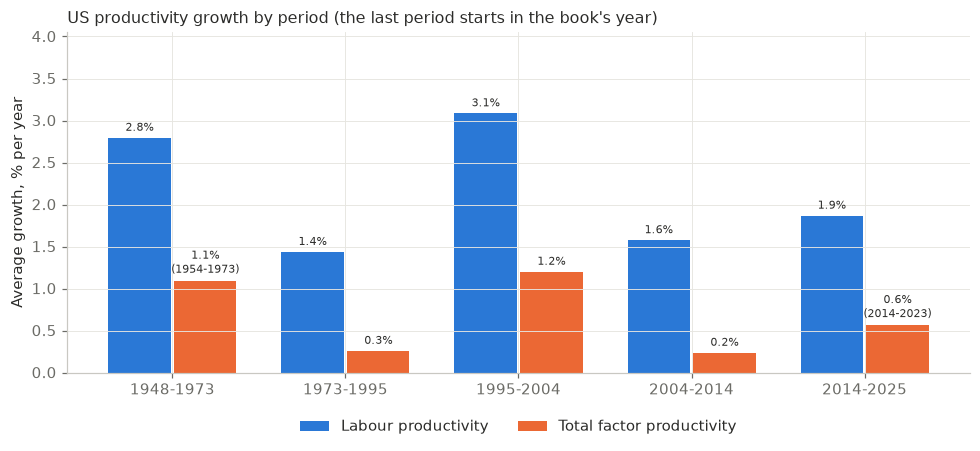

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
periods = g_lp.period.tolist()
x = np.arange(len(periods))
for i, (lab, g) in enumerate([("Labour productivity", g_lp), ("Total factor productivity", g_tfp)]):
    g = g.reset_index(drop=True)
    for k, row in g.iterrows():                               # rows are in the same period order for both measures
        xi = x[k] + (i - 0.5) * 0.38
        ax.bar(xi, row.growth_pct_per_year, width=0.36, color=tc.C[i], label=lab if k == 0 else None)
        note = "" if row.period == periods[k] else f"\n({row.period})"
        ax.text(xi, row.growth_pct_per_year + 0.05, f"{row.growth_pct_per_year:.1f}%{note}", ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(periods); ax.axhline(0, color=tc.INK, lw=0.6)
ax.set_ylabel("Average growth, % per year"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_ylim(min(0, ax.get_ylim()[0]), ax.get_ylim()[1] * 1.25)
ax.set_title("US productivity growth by period (the last period starts in the book's year)", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h6_fig1_productivity")

## H6b · Bits against atoms: prices relative to the CPI

Each series is the BLS consumer price index for that item, divided by the all-items CPI and set to 100 in the base year. A falling line means the item got cheaper relative to everything else.

In [4]:
ITEMS = {  # FRED id: (label, group)
    "CUUR0000SEEE01": ("Computers and peripherals", "bits"),
    "CUUR0000SEEE02": ("Computer software and accessories", "bits"),
    "CUUR0000SERA01": ("Televisions", "bits"),
    "CUUR0000SEED03": ("Wireless phone services", "bits"),
    "CUUR0000SEEB01": ("College tuition and fees", "atoms"),
    "CPIMEDSL":       ("Medical care", "atoms"),
    "CUUR0000SEHA":   ("Rent of primary residence", "atoms"),
    "CUUR0000SETG01": ("Airline fares", "atoms"),
    "CUUR0000SEHF01": ("Electricity", "atoms"),
    "CUUR0000SETA01": ("New vehicles", "atoms"),
    "CUUR0000SAF11":  ("Food at home", "atoms"),
}
cpi = annual(tc.fred("CPIAUCNS"))
END = int(cpi.index.max())
rel, missing = {}, []
for sid, (lab, grp) in ITEMS.items():
    s = tc.fred(sid)
    if s.empty: missing.append(sid); continue
    a = annual(s)
    rel[sid] = (a / cpi.reindex(a.index)).dropna()
if missing: print("FRED did not return:", missing)
def ann_change(r, a0, a1):
    if a0 in r.index and a1 in r.index: return 100 * ((r[a1] / r[a0]) ** (1 / (a1 - a0)) - 1)
    return np.nan
rows = []
for sid, r in rel.items():
    lab, grp = ITEMS[sid]
    rows.append({"item": lab, "group": grp, "first_year": int(r.index.min()),
                 "real_change_2000_2014_pct_yr": ann_change(r, 2000, 2014),
                 f"real_change_2014_{END}_pct_yr": ann_change(r, 2014, END),
                 f"cumulative_2014_{END}_pct": 100 * (r[END] / r[2014] - 1) if 2014 in r.index and END in r.index else np.nan})
bva = pd.DataFrame(rows).sort_values(["group", f"real_change_2014_{END}_pct_yr"])
tc.save_table(bva, "h6b_bits_vs_atoms", index=False)
grp_avg = bva.groupby("group")[["real_change_2000_2014_pct_yr", f"real_change_2014_{END}_pct_yr"]].mean()
print(grp_avg.round(2).to_string())
bva.round(2)

       real_change_2000_2014_pct_yr  real_change_2014_2025_pct_yr
group                                                            
atoms                          0.66                         -0.71
bits                         -11.71                         -7.98


,item,group,first_year,real_change_2000_2014_pct_yr,real_change_2014_2025_pct_yr,cumulative_2014_2025_pct
7,Airline fares,atoms,1963,-0.48,-4.36,-38.80
9,New vehicles,atoms,1947,-2.08,-0.98,-10.29
4,College tuition and fees,atoms,1997,3.71,-0.71,-7.51
10,Food at home,atoms,1947,0.26,-0.35,-3.80
5,Medical care,atoms,1947,1.40,-0.18,-2.01
8,Electricity,atoms,1913,1.18,0.29,3.23
6,Rent of primary residence,atoms,1914,0.63,1.34,15.80
2,Televisions,bits,1997,-18.47,-14.26,-81.58
1,Computer software and accessories,bits,1997,-7.92,-6.71,-53.41
0,Computers and peripherals,bits,1997,-16.27,-6.35,-51.41


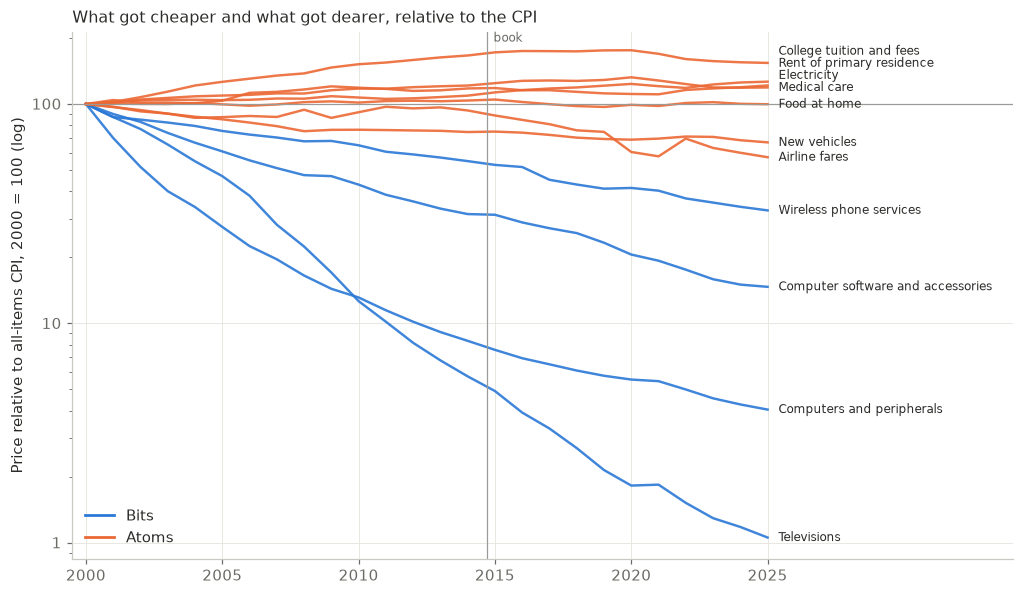

In [5]:
BASE = 2000
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ends = []
for sid, r in rel.items():
    lab, grp = ITEMS[sid]
    b = BASE if BASE in r.index else int(r.index.min())
    rr = 100 * r.loc[b:] / r[b]
    col = tc.C[0] if grp == "bits" else tc.C[1]
    ax.plot(rr.index, rr.values, color=col, lw=1.6, alpha=0.9)
    ends.append([rr.values[-1], lab + ("" if b == BASE else f" (from {b})"), col])
ends.sort(key=lambda e: e[0])
ypos = []
for v, lab, col in ends:                                   # spread end labels so they do not collide (log space)
    y = np.log10(v)
    if ypos and y - ypos[-1] < 0.055: y = ypos[-1] + 0.055
    ypos.append(y)
    ax.text(END + 0.4, 10 ** y, lab, va="center", fontsize=7.8, color=tc.INK)
lo = min(e[0] for e in ends); allv = np.concatenate([100 * (r.loc[(BASE if BASE in r.index else int(r.index.min())):] /
       r[BASE if BASE in r.index else int(r.index.min())]).values for r in rel.values()])
ax.set_ylim(min(allv.min(), lo) * 0.8, max(allv.max(), 10 ** (max(ypos) + 0.04)) * 1.12)   # explicit: log axes must stay > 0
ax.set_xticks(range(BASE, END + 1, 5))
ax.set_yscale("log"); ax.axhline(100, color=tc.GREY, lw=0.8)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.yaxis.set_minor_formatter(NullFormatter())
ax.axvline(2014.7, color=tc.GREY, lw=0.8); ax.text(2014.8, ax.get_ylim()[1], " book", fontsize=8, va="top", color=tc.MUTED)
ax.set_xlim(BASE - 0.5, END + 9)
ax.set_ylabel(f"Price relative to all-items CPI, {BASE} = 100 (log)")
ax.plot([], [], color=tc.C[0], label="Bits"); ax.plot([], [], color=tc.C[1], label="Atoms"); ax.legend(loc="lower left")
ax.set_title("What got cheaper and what got dearer, relative to the CPI", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h6_fig2_bits_atoms")

## H6c · Where business investment goes

Nominal shares of private nonresidential fixed investment. Intellectual property products are software, R&D, and entertainment and artistic originals.

      Structures  Equipment  Intellectual property products
date                                                       
1950        33.2       59.3                             7.5
1970        32.3       53.3                            14.4
1990        27.4       50.3                            22.2
2000        21.4       51.1                            27.5
2014        23.7       45.7                            30.6
2025        21.9       38.5                            39.6


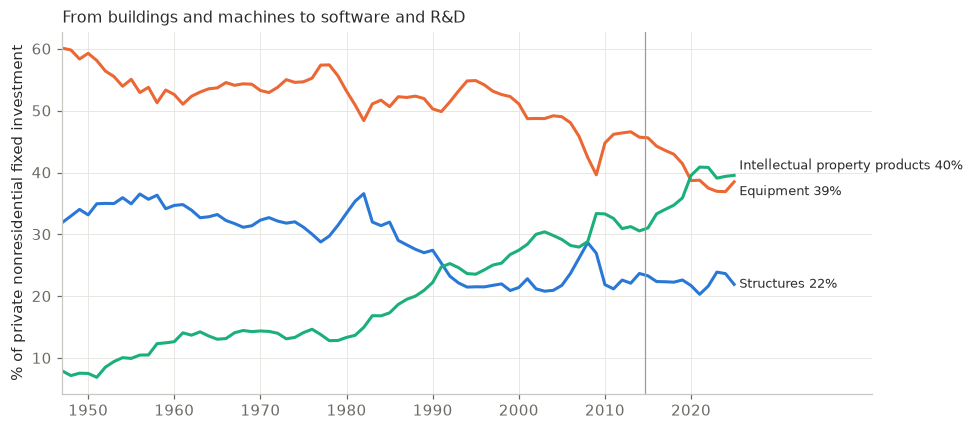

In [6]:
inv = {"Structures": "B009RC1Q027SBEA", "Equipment": "Y033RC1Q027SBEA", "Intellectual property products": "Y001RC1Q027SBEA"}
tot = annual(tc.fred("PNFI"))
shares = pd.DataFrame({k: annual(tc.fred(v)) for k, v in inv.items()}).div(tot, axis=0).dropna() * 100
tc.save_table(shares, "h6c_investment_shares")
pick = [y for y in (1950, 1970, 1990, 2000, 2014, int(shares.index.max())) if y in shares.index]
print(shares.loc[pick].round(1).to_string())
fig, ax = plt.subplots(figsize=(9, 4))
for i, c in enumerate(shares.columns):
    ax.plot(shares.index, shares[c], color=tc.C[i], lw=2)
    last_vals = shares.iloc[-1].sort_values()
    yv = shares[c].iloc[-1] + (1.6 if c == last_vals.index[-1] and last_vals.iloc[-1] - last_vals.iloc[-2] < 3 else
                               -1.6 if c == last_vals.index[-2] and last_vals.iloc[-1] - last_vals.iloc[-2] < 3 else 0)
    ax.text(shares.index[-1] + 0.6, yv, f"{c} {shares[c].iloc[-1]:.0f}%", va="center", fontsize=8.5)
ax.axvline(2014.7, color=tc.GREY, lw=0.8); ax.set_xlim(shares.index.min(), shares.index.max() + 16)
ax.set_xticks([y for y in range(1950, int(shares.index.max()) + 1, 10)])
ax.set_ylabel("% of private nonresidential fixed investment")
ax.set_title("From buildings and machines to software and R&D", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h6_fig3_investment")

## H6d · Medicine: US life expectancy at birth

,period,years_gained,per_decade
0,1960-1970,1.04,1.04
1,1970-1980,2.80,2.80
2,1980-1990,1.60,1.60
3,1990-2000,1.42,1.42
4,2000-2010,1.90,1.90
5,2010-2019,0.25,0.27
6,2014-2019,-0.05,-0.11
7,2019-2021,-2.46,-12.29
8,2021-2024,2.56,8.54
9,2014-2024,0.05,0.05


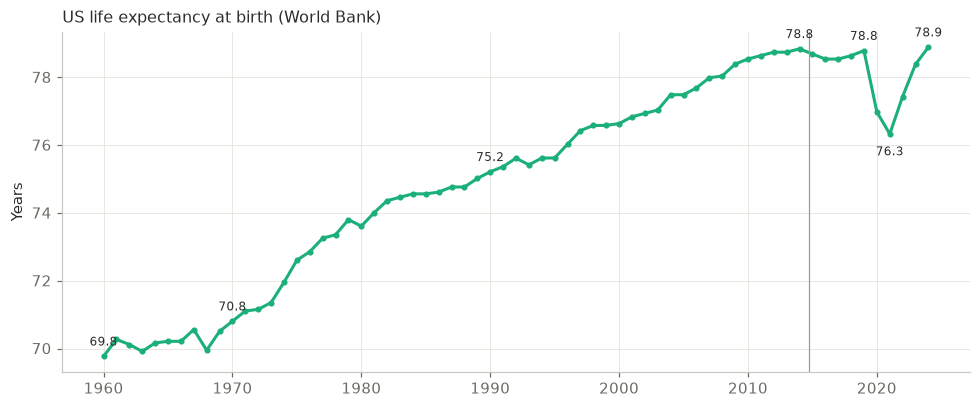

In [7]:
le = tc.fred("SPDYNLE00INUSA"); le = le.groupby(le.index.year).mean()
LAST = int(le.index.max())
spans = [(1960, 1970), (1970, 1980), (1980, 1990), (1990, 2000), (2000, 2010), (2010, 2019),   # 2019: last pre-pandemic year
         (2014, 2019), (2019, 2021), (2021, LAST), (2014, LAST)]
dec = []
for a0, a1 in spans:
    if a0 in le.index and a1 in le.index and a1 > a0:
        dec.append({"period": f"{a0}-{a1}", "years_gained": le[a1] - le[a0], "per_decade": (le[a1] - le[a0]) * 10 / (a1 - a0)})
dec = pd.DataFrame(dec); tc.save_table(dec, "h6d_life_expectancy", index=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(le.index, le.values, color=tc.C[2], lw=2, marker="o", ms=3)
for y, off in [(1960, 7), (1970, 7), (1990, 7), (2014, 7), (2019, 7), (2021, -14), (int(le.index.max()), 7)]:
    if y in le.index: ax.annotate(f"{le[y]:.1f}", (y, le[y]), xytext=(0, off), textcoords="offset points", ha="center", fontsize=8)
ax.axvline(2014.7, color=tc.GREY, lw=0.8)
ax.set_ylabel("Years"); ax.set_title("US life expectancy at birth (World Bank)", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h6_fig4_life_expectancy")
dec.round(2)

## Verdict inputs and check cell — send me this output

In [8]:
rec = lambda df: json.loads(df.round(3).to_json(orient="records"))
summary = {
    "productivity": rec(prod), "productivity_recent": rec(recent), "productivity_post2014_ex_covid": rec(g_lp_ex),
    "bits_vs_atoms": rec(bva), "group_avg": json.loads(grp_avg.round(3).to_json(orient="index")), "missing": missing,
    "investment_shares": json.loads(shares.loc[pick].round(2).to_json(orient="index")),
    "life_expectancy": rec(dec), "le_latest": [int(le.index.max()), round(float(le.iloc[-1]), 2)],
    "le_2014_2019": [round(float(le.get(2014, np.nan)), 2), round(float(le.get(2019, np.nan)), 2)],
}
(tc.OUT / "h6_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(json.dumps(summary, indent=1, default=str)[:5000])

{
 "productivity": [
  {
   "period": "1948-1973",
   "start": 1948,
   "end": 1973,
   "growth_pct_per_year": 2.795,
   "measure": "Labour productivity (nonfarm business)"
  },
  {
   "period": "1973-1995",
   "start": 1973,
   "end": 1995,
   "growth_pct_per_year": 1.436,
   "measure": "Labour productivity (nonfarm business)"
  },
  {
   "period": "1995-2004",
   "start": 1995,
   "end": 2004,
   "growth_pct_per_year": 3.086,
   "measure": "Labour productivity (nonfarm business)"
  },
  {
   "period": "2004-2014",
   "start": 2004,
   "end": 2014,
   "growth_pct_per_year": 1.576,
   "measure": "Labour productivity (nonfarm business)"
  },
  {
   "period": "2014-2025",
   "start": 2014,
   "end": 2025,
   "growth_pct_per_year": 1.868,
   "measure": "Labour productivity (nonfarm business)"
  },
  {
   "period": "1954-1973",
   "start": 1954,
   "end": 1973,
   "growth_pct_per_year": 1.092,
   "measure": "Total factor productivity (Penn World Table)"
  },
  {
   "period": "1973-1995",
 